# NLP clásico aplicado a IMDB: Bag of Words y TF-IDF

**Dataset:** `movie_review_kaggle.csv.gz`  
**Problema:** clasificación de sentimiento en reseñas de películas.  
**Modelo de clasificación:** Logistic Regression.  
**Representaciones estudiadas:** **Bag of Words (BoW)** y **TF-IDF**.

Este notebook conserva el dataset y el flujo general de la versión original, pero concentra la clase en dos representaciones fundamentales del lenguaje: contar palabras y ponderar su importancia.

---

## Objetivos de aprendizaje

Al finalizar el notebook, el estudiante estará en capacidad de:

1. Realizar una exploración básica de un corpus textual.
2. Identificar ruido, documentos duplicados, longitudes extremas y palabras frecuentes.
3. Aplicar una limpieza de texto apropiada para análisis de sentimiento.
4. Explicar matemáticamente cómo se construye una matriz documento–término.
5. Representar documentos con Bag of Words.
6. Explicar y calcular la intuición de TF, DF, IDF y TF-IDF.
7. Entrenar y evaluar clasificadores usando ambas representaciones.
8. Interpretar las palabras más influyentes y analizar errores del modelo.

---

## Ruta sugerida para una clase de 60 minutos

| Bloque | Tiempo |
|---|---:|
| Contexto, carga y EDA | 10 min |
| Limpieza del texto | 10 min |
| Bag of Words | 15 min |
| TF-IDF | 15 min |
| Comparación, interpretación y cierre | 10 min |

# 0. Configuración inicial

Un pipeline reproducible debe dejar explícitos:

- El archivo utilizado.
- Las columnas de texto y etiqueta.
- Las reglas de limpieza.
- La división de entrenamiento y prueba.
- La semilla aleatoria.
- Las métricas de evaluación.

El dataset se mantiene igual al de la versión entregada: `movie_review_kaggle.csv.gz`.

In [3]:
# ============================================================
# 0.1 Imports generales
# ============================================================

import os
import re
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 180)

In [4]:
# ============================================================
# 0.2 Cargar el mismo dataset de la versión original
# ============================================================

DATA_PATH = "movie_review_kaggle.csv.gz"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"No se encontró '{DATA_PATH}'. "
        "Coloque el archivo en la misma carpeta del notebook."
    )

df_raw = pd.read_csv(DATA_PATH)
print("Dimensión original:", df_raw.shape)
df_raw.head(10)

Dimensión original: (10000, 2)


,review,sentiment
0,"I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting to me for some reason. Anyways, this could have been one of ...",positive
1,Not many television shows appeal to quite as many different kinds of fans like Farscape does...I know youngsters and 30/40+ years old;fans both Male and Female in as many diffe...,positive
2,The film quickly gets to a major chase scene with ever increasing destruction. The first really bad thing is the guy hijacking Steven Seagal would have been beaten to pulp by S...,negative
3,"Jane Austen would definitely approve of this one!<br /><br />Gwyneth Paltrow does an awesome job capturing the attitude of Emma. She is funny without being excessively silly, y...",positive
4,"Expectations were somewhat high for me when I went to see this movie, after all I thought Steve Carell could do no wrong coming off of great movies like Anchorman, The 40 Year-...",negative
5,"I've watched this movie on a fairly regular basis for most of my life, and it never gets old. For all the snide remarks and insults (mostly from David Spade), ""Tommy Boy"" has a...",positive
6,"For once a story of hope highlighted over the tragic reality our youth face. Favela Rising draws one into a scary, unsafe and unfair world and shows through beautiful color and...",positive
7,"Okay, I didn't get the Purgatory thing the first time I watched this episode. It seemed like something significant was going on that I couldn't put my finger on. This time thos...",positive
8,"I was very disappointed with this series. It had lots of cool graphics and that's about it. The level of detail it went into was minimal, and I always got the feeling the audie...",negative
9,"The first 30 minutes of Tinseltown had my finger teetering on the remote, poised to flick around to watch something else. The premise of two writers, down on their luck, living...",negative


## 0.3 Definición y validación de columnas

El dataset debe contener:

- `review`: texto de la reseña.
- `sentiment`: etiqueta, normalmente `positive` o `negative`.

Se crea además una variable numérica `target`:

$$
\text{negative}=0, \qquad \text{positive}=1
$$

Conservaremos una copia del dataset original en `df_raw` y utilizaremos `df` para el análisis.


In [5]:
TEXT_COL = "review"
LABEL_COL = "sentiment"
TARGET_COL = "target"

required_columns = {TEXT_COL, LABEL_COL}
missing_columns = required_columns - set(df_raw.columns)

if missing_columns:
    raise ValueError(f"Faltan columnas requeridas: {missing_columns}")

df = df_raw.copy()

# Normalización robusta de etiquetas
df["sentiment_label"] = df[LABEL_COL].astype(str).str.strip().str.lower()

label_map = {
    "negative": 0,
    "positive": 1,
    "0": 0,
    "1": 1
}
df[TARGET_COL] = df["sentiment_label"].map(label_map)

if df[TARGET_COL].isna().any():
    unknown = df.loc[df[TARGET_COL].isna(), LABEL_COL].drop_duplicates().tolist()
    raise ValueError(f"Se encontraron etiquetas no reconocidas: {unknown}")

df[TARGET_COL] = df[TARGET_COL].astype(int)

df[[TEXT_COL, LABEL_COL, "sentiment_label", TARGET_COL]].head()

,review,sentiment,sentiment_label,target
0,"I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting to me for some reason. Anyways, this could have been one of ...",positive,positive,1
1,Not many television shows appeal to quite as many different kinds of fans like Farscape does...I know youngsters and 30/40+ years old;fans both Male and Female in as many diffe...,positive,positive,1
2,The film quickly gets to a major chase scene with ever increasing destruction. The first really bad thing is the guy hijacking Steven Seagal would have been beaten to pulp by S...,negative,negative,0
3,"Jane Austen would definitely approve of this one!<br /><br />Gwyneth Paltrow does an awesome job capturing the attitude of Emma. She is funny without being excessively silly, y...",positive,positive,1
4,"Expectations were somewhat high for me when I went to see this movie, after all I thought Steve Carell could do no wrong coming off of great movies like Anchorman, The 40 Year-...",negative,negative,0


# 1. Exploración de datos textuales

En datos tabulares solemos revisar distribuciones numéricas. En NLP también necesitamos estudiar:

- Cantidad de documentos.
- Balance de clases.
- Valores faltantes y duplicados.
- Longitud de las reseñas.
- Presencia de HTML, URLs u otros patrones.
- Frecuencias de palabras.
- Tamaño y dispersión potencial del vocabulario.

Estas decisiones influyen directamente en BoW y TF-IDF porque ambas técnicas construyen una columna por término del vocabulario.

In [6]:
# ============================================================
# 1.1 Calidad básica de datos
# ============================================================

quality_summary = pd.DataFrame({
    "métrica": [
        "filas",
        "columnas",
        "reviews nulas",
        "etiquetas nulas",
        "reviews duplicadas",
        "pares review-etiqueta duplicados"
    ],
    "valor": [
        len(df),
        df.shape[1],
        df[TEXT_COL].isna().sum(),
        df[LABEL_COL].isna().sum(),
        df.duplicated(subset=[TEXT_COL]).sum(),
        df.duplicated(subset=[TEXT_COL, LABEL_COL]).sum()
    ]
})

display(quality_summary)

,métrica,valor
0,filas,10000
1,columnas,4
2,reviews nulas,0
3,etiquetas nulas,0
4,reviews duplicadas,22
5,pares review-etiqueta duplicados,22


### Decisión sobre nulos y duplicados

Los documentos nulos no pueden vectorizarse. Además, reseñas duplicadas pueden aparecer tanto en entrenamiento como en prueba y producir una evaluación demasiado optimista.

Por ello:

1. Eliminamos filas sin texto o etiqueta.
2. Eliminamos duplicados exactos de `review` y `sentiment`.
3. Conservamos el mismo dataset de origen; únicamente creamos una versión válida para modelado.

In [7]:
rows_before = len(df)

df = (
    df.dropna(subset=[TEXT_COL, LABEL_COL])
      .drop_duplicates(subset=[TEXT_COL, LABEL_COL])
      .reset_index(drop=True)
)

rows_after = len(df)

print("Filas antes:", rows_before)
print("Filas después:", rows_after)
print("Filas removidas:", rows_before - rows_after)

Filas antes: 10000
Filas después: 9978
Filas removidas: 22


,sentiment,reviews,proporción
0,positive,5035,0.50461
1,negative,4943,0.49539


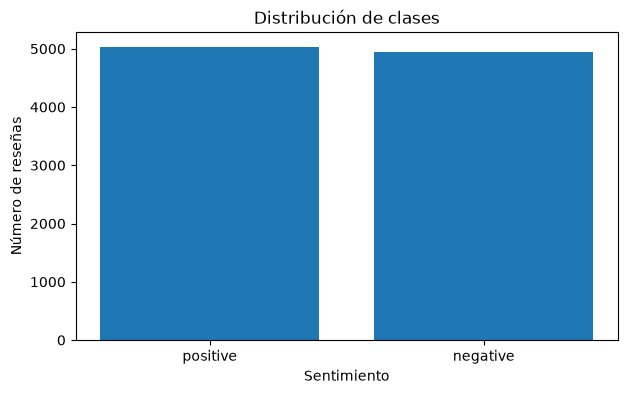

In [8]:
# ============================================================
# 1.2 Balance de clases
# ============================================================

class_counts = (
    df["sentiment_label"]
    .value_counts()
    .rename_axis("sentiment")
    .reset_index(name="reviews")
)

class_counts["proporción"] = class_counts["reviews"] / class_counts["reviews"].sum()
display(class_counts)

plt.figure(figsize=(7, 4))
plt.bar(class_counts["sentiment"], class_counts["reviews"])
plt.title("Distribución de clases")
plt.xlabel("Sentimiento")
plt.ylabel("Número de reseñas")
plt.show()

## Ejercicio 1

1. ¿Cuántas reseñas válidas quedan?
2. ¿El problema está aproximadamente balanceado?
3. ¿Por qué un conjunto muy desbalanceado puede hacer que `accuracy` sea engañosa?

In [9]:
# ============================================================
# 1.3 Longitud de los documentos
# ============================================================

df["num_chars"] = df[TEXT_COL].astype(str).apply(len)
df["num_words"] = df[TEXT_COL].astype(str).apply(lambda text: len(text.split()))

display(df[[TEXT_COL, "sentiment_label", "num_chars", "num_words"]].head())

print("Estadísticas generales:")
display(df[["num_chars", "num_words"]].describe().round(2))

print("Promedios por clase:")
display(
    df.groupby("sentiment_label")[["num_chars", "num_words"]]
      .mean()
      .round(2)
)

,review,sentiment_label,num_chars,num_words
0,"I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting to me for some reason. Anyways, this could have been one of ...",positive,1107,201
1,Not many television shows appeal to quite as many different kinds of fans like Farscape does...I know youngsters and 30/40+ years old;fans both Male and Female in as many diffe...,positive,2054,354
2,The film quickly gets to a major chase scene with ever increasing destruction. The first really bad thing is the guy hijacking Steven Seagal would have been beaten to pulp by S...,negative,653,119
3,"Jane Austen would definitely approve of this one!<br /><br />Gwyneth Paltrow does an awesome job capturing the attitude of Emma. She is funny without being excessively silly, y...",positive,632,99
4,"Expectations were somewhat high for me when I went to see this movie, after all I thought Steve Carell could do no wrong coming off of great movies like Anchorman, The 40 Year-...",negative,1900,332


Estadísticas generales:


,num_chars,num_words
count,9978.00,9978.00
mean,1314.16,231.88
std,984.05,170.41
min,41.00,9.00
25%,700.00,126.00
50%,975.00,173.00
75%,1596.00,282.00
max,7164.00,1316.00


Promedios por clase:


,num_chars,num_words
sentiment_label,,
negative,1305.51,231.31
positive,1322.66,232.43


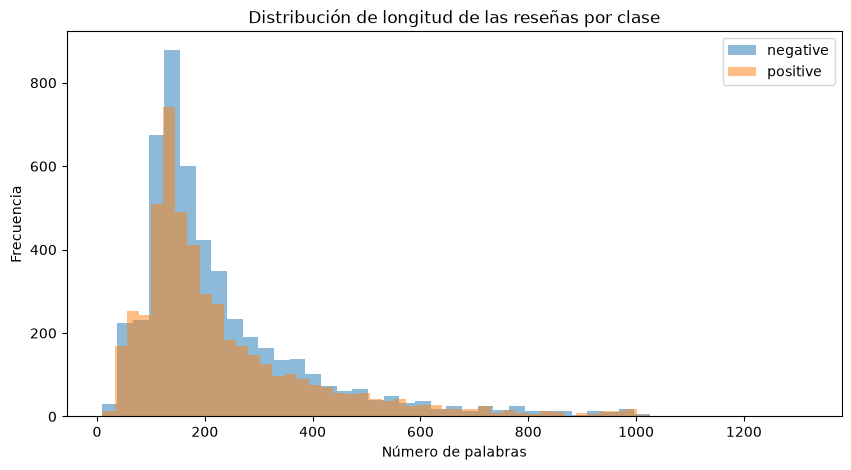

In [10]:
plt.figure(figsize=(10, 5))

for label in sorted(df["sentiment_label"].unique()):
    subset = df.loc[df["sentiment_label"] == label, "num_words"]
    plt.hist(subset, bins=45, alpha=0.5, label=label)

plt.title("Distribución de longitud de las reseñas por clase")
plt.xlabel("Número de palabras")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

In [11]:
# Reseñas particularmente cortas o largas
display(
    df.nsmallest(5, "num_words")[
        [TEXT_COL, "sentiment_label", "num_words"]
    ]
)

display(
    df.nlargest(5, "num_words")[
        [TEXT_COL, "sentiment_label", "num_words"]
    ]
)

,review,sentiment_label,num_words
5719,"What a script, what a story, what a mess!",negative,9
6495,Brilliant and moving performances by Tom Courtenay and Peter Finch.,positive,10
5987,Adrian Pasdar is excellent is this film. He makes a fascinating woman.,positive,12
8415,This is a great movie. Too bad it is not available on home video.,positive,14
4894,Absolutely fantastic! Whatever I say wouldn't do this underrated movie the justice it deserves. Watch it now! FANTASTIC!,positive,18


,review,sentiment_label,num_words
8356,"Okay, so I'm not a big video game buff, but was the game House of the Dead really famous enough to make a movie from? Sure, they went as far as to actually put in quick video g...",negative,1316
3801,"If you've seen the trailer for this movie, you pretty much know what to expect, because what you see here is what you get. And even if you haven't seen the previews, it won't t...",positive,1024
585,"Warning: Spoilers Galore!<br /><br />Tim Burton remaking this sui generis movie is about as sensible as remaking Psycho - oh, that's right, some idiot already did that - I rest...",negative,1010
6187,"The vigilante has long held a fascination for audiences, inasmuch as it evokes a sense of swift, sure justice; good triumphs over evil and the bad guy gets his deserts. It is, ...",positive,1007
9626,"How strange the human mind is; this center of activity wherein perceptions of reality are formed and stored, and in which one's view of the world hinges on the finely tuned fun...",positive,1006


## 1.4 Ruido visible en el texto

Las reseñas de IMDB pueden contener marcas HTML como `<br />`. También pueden aparecer URLs, números o puntuación repetida.

Antes de limpiar, conviene medir el problema en lugar de asumir que existe.

In [12]:
def contains_html(text):
    return bool(re.search(r"<[^>]+>", str(text)))

def contains_url(text):
    return bool(re.search(r"https?://\S+|www\.\S+", str(text)))

df["has_html"] = df[TEXT_COL].apply(contains_html)
df["has_url"] = df[TEXT_COL].apply(contains_url)

noise_summary = pd.DataFrame({
    "patrón": ["HTML", "URL"],
    "documentos": [df["has_html"].sum(), df["has_url"].sum()],
    "porcentaje": [
        100 * df["has_html"].mean(),
        100 * df["has_url"].mean()
    ]
})

display(noise_summary.round(2))

,patrón,documentos,porcentaje
0,HTML,5868,58.81
1,URL,32,0.32


## 1.5 Frecuencias de palabras

Las frecuencias ofrecen una primera aproximación al contenido del corpus. Sin embargo:

- Las palabras funcionales suelen dominar los conteos.
- Una palabra frecuente no es necesariamente discriminativa.
- Una palabra rara puede ser ruido o una señal específica.
- Estas observaciones motivan posteriormente el uso de TF-IDF.

In [16]:
def simple_tokenize(text):
    """Tokenización sencilla para EDA; no reemplaza un tokenizer lingüístico."""
    return re.findall(r"\b[a-zA-Z]+\b", str(text).lower())


def get_top_words(texts, n=20, remove_stopwords=False):
    all_words = []

    for text in texts:
        tokens = simple_tokenize(text)

        if remove_stopwords:
            tokens = [
                word for word in tokens
                if word not in ENGLISH_STOP_WORDS
            ]

        all_words.extend(tokens)

    return Counter(all_words).most_common(n)


def plot_top_words(top_words, title):
    words = [word for word, _ in top_words]
    counts = [count for _, count in top_words]

    plt.figure(figsize=(11, 5))
    plt.bar(words, counts)
    plt.title(title)
    plt.xlabel("Palabra")
    plt.ylabel("Frecuencia")
    plt.xticks(rotation=45, ha="right")
    plt.show()

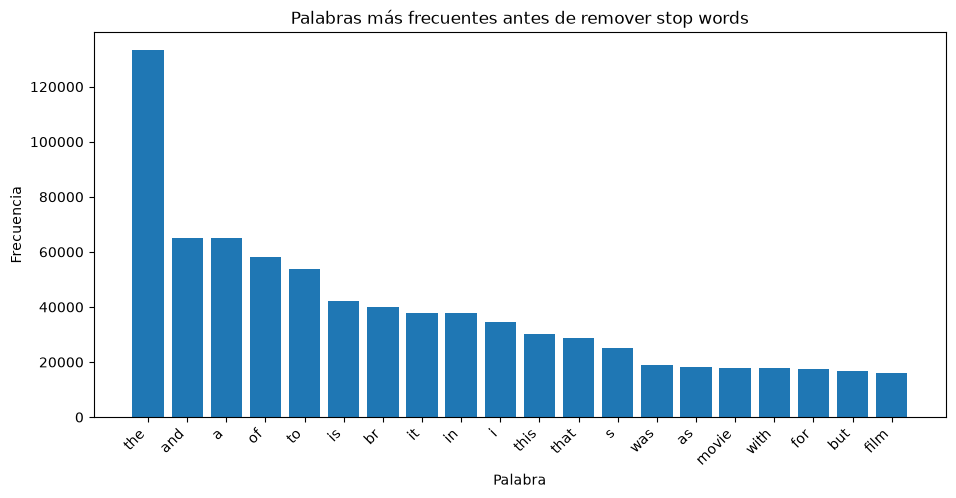

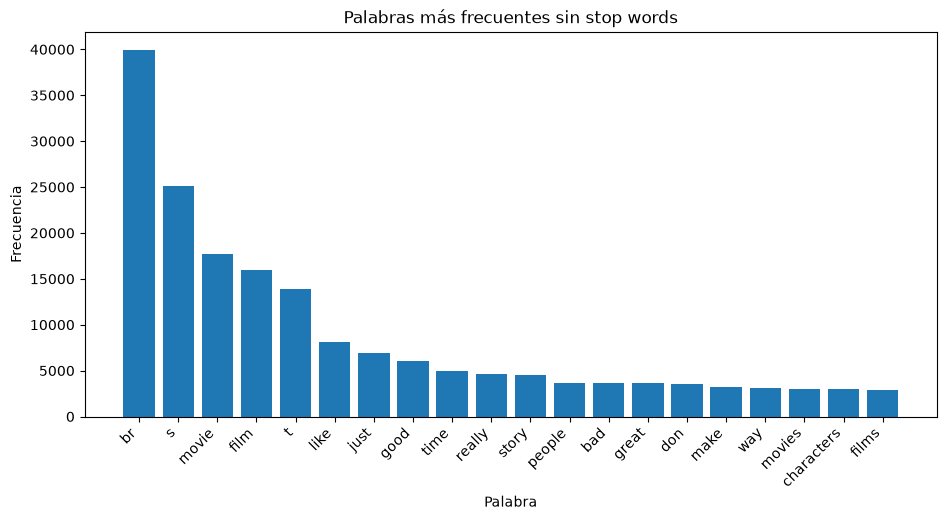

In [17]:
top_raw = get_top_words(df[TEXT_COL], n=20, remove_stopwords=False)
top_without_stopwords = get_top_words(
    df[TEXT_COL], n=20, remove_stopwords=True
)

plot_top_words(
    top_raw,
    "Palabras más frecuentes antes de remover stop words"
)

plot_top_words(
    top_without_stopwords,
    "Palabras más frecuentes sin stop words"
)

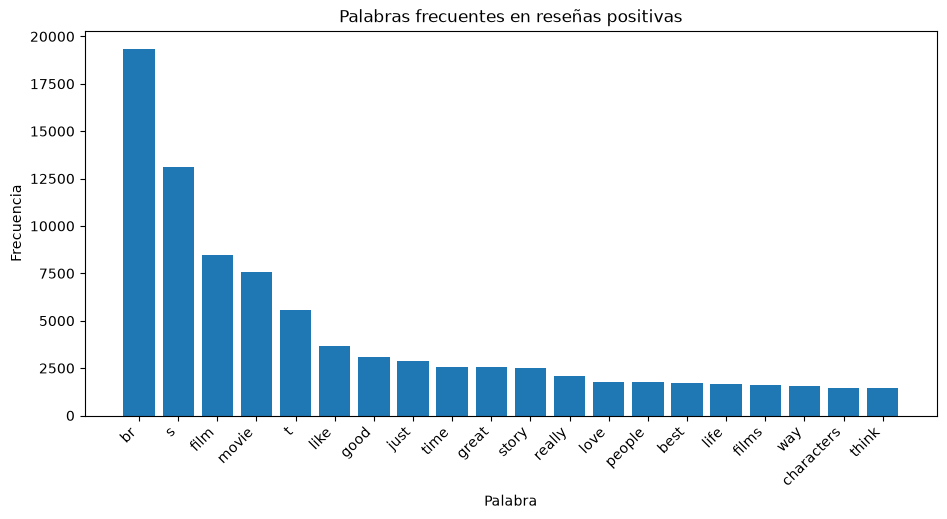

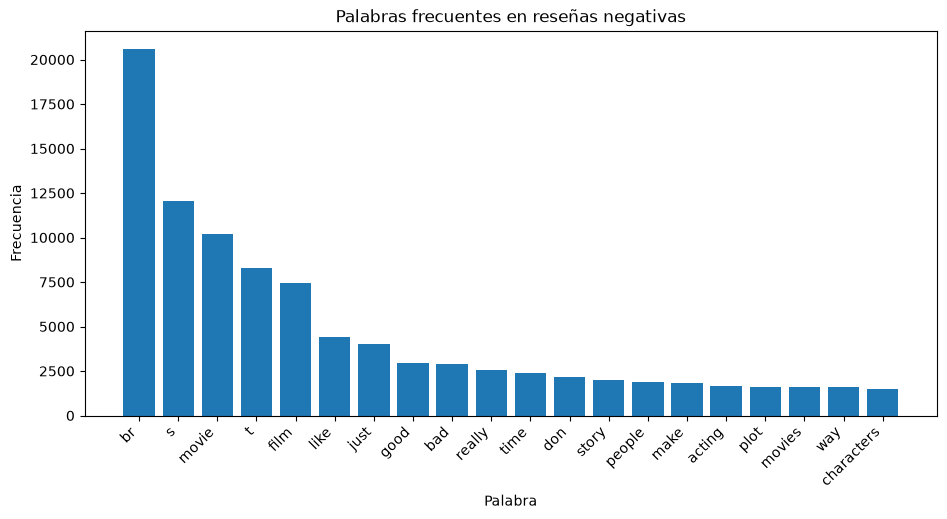

In [18]:
top_positive = get_top_words(
    df.loc[df["sentiment_label"] == "positive", TEXT_COL],
    n=20,
    remove_stopwords=True
)

top_negative = get_top_words(
    df.loc[df["sentiment_label"] == "negative", TEXT_COL],
    n=20,
    remove_stopwords=True
)

plot_top_words(
    top_positive,
    "Palabras frecuentes en reseñas positivas"
)

plot_top_words(
    top_negative,
    "Palabras frecuentes en reseñas negativas"
)

### Vocabulario y palabras raras

Si el vocabulario tiene $m$ términos, cada documento se representa con un vector de dimensión $m$.

En un corpus real:

- Un pequeño grupo de palabras aparece muchas veces.
- Una gran cantidad de palabras aparece muy pocas veces.
- Esto produce vectores de alta dimensión con muchos ceros.

Esa estructura se denomina **matriz dispersa**.

In [19]:
all_tokens = []

for text in df[TEXT_COL]:
    all_tokens.extend(simple_tokenize(text))

word_counts = Counter(all_tokens)

total_unique_words = len(word_counts)
words_once = [word for word, count in word_counts.items() if count == 1]
num_words_once = len(words_once)

vocabulary_summary = pd.DataFrame({
    "métrica": [
        "tokens totales",
        "palabras únicas",
        "palabras que aparecen una sola vez",
        "porcentaje del vocabulario con frecuencia 1"
    ],
    "valor": [
        len(all_tokens),
        total_unique_words,
        num_words_once,
        100 * num_words_once / total_unique_words
    ]
})

display(vocabulary_summary.round(2))
print("Ejemplos de palabras con frecuencia 1:")
print(words_once[:40])

,métrica,valor
0,tokens totales,2381850.00
1,palabras únicas,51380.00
2,palabras que aparecen una sola vez,19387.00
3,porcentaje del vocabulario con frecuencia 1,37.73


Ejemplos de palabras con frecuencia 1:
['hening', 'harts', 'ludvig', 'borga', 'jannetty', 'gunns', 'hardiest', 'brainbender', 'equational', 'kaos', 'nationally', 'crossword', 'belabor', 'funnybone', 'subversively', 'favela', 'mesa', 'twop', 'hunch', 'purgatorio', 'iffy', 'melfi', 'receptionists', 'infinnerty', 'infiniti', 'aaaand', 'patronized', 'sparticles', 'vibrating', 'teetering', 'swansons', 'stuttured', 'whithnail', 'skikkelig', 'gebrokkent', 'degression', 'aproved', 'grassy', 'coloric', 'mindstate']


## Ejercicio 2

1. Compare las palabras frecuentes de ambas clases.
2. ¿Cuáles aparecen en las dos listas?
3. ¿Por qué la frecuencia bruta no basta para determinar importancia?
4. ¿Qué efecto puede tener un vocabulario con miles de palabras raras?

# 2. Normalización y limpieza

La limpieza busca reducir variaciones que no aportan al problema. No obstante, **limpiar más no siempre significa modelar mejor**.

Para análisis de sentimiento debemos tener especial cuidado con las negaciones:

> `not good` no significa lo mismo que `good`.

La limpieza aplicada será deliberadamente conservadora:

1. Minúsculas.
2. Eliminación de HTML y URLs.
3. Conversión de contracciones terminadas en `n't` a `not`.
4. Eliminación de caracteres no alfabéticos.
5. Eliminación de stop words, conservando negaciones.
6. Sin stemming ni lematización, para mantener el foco en BoW y TF-IDF.

In [20]:
NEGATIONS_TO_KEEP = {"no", "not", "nor", "never"}
CUSTOM_STOP_WORDS = set(ENGLISH_STOP_WORDS) - NEGATIONS_TO_KEEP


def clean_text(text):
    """Limpieza conservadora para análisis de sentimiento en inglés."""

    text = str(text).lower()

    # HTML y URLs
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Preservar la información de negación:
    # wasn't -> was not, didn't -> did not, isn't -> is not
    text = re.sub(r"n['’]t\b", " not", text)

    # Solo letras y espacios
    text = re.sub(r"[^a-z\s]", " ", text)

    tokens = text.split()

    tokens = [
        token for token in tokens
        if token not in CUSTOM_STOP_WORDS
    ]

    return " ".join(tokens)


df["review_clean"] = df[TEXT_COL].apply(clean_text)
df["num_words_clean"] = df["review_clean"].apply(lambda text: len(text.split()))

display(
    df[[TEXT_COL, "review_clean", "sentiment_label"]].head(8)
)

,review,review_clean,sentiment_label
0,"I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting to me for some reason. Anyways, this could have been one of ...",really liked summerslam look arena curtains just look overall interesting reason anyways best summerslam s wwf did not lex luger main event yokozuna s time ok huge fat man vs s...,positive
1,Not many television shows appeal to quite as many different kinds of fans like Farscape does...I know youngsters and 30/40+ years old;fans both Male and Female in as many diffe...,not television shows appeal quite different kinds fans like farscape does know youngsters years old fans male female different countries think just adore t v miniseries element...,positive
2,The film quickly gets to a major chase scene with ever increasing destruction. The first really bad thing is the guy hijacking Steven Seagal would have been beaten to pulp by S...,film quickly gets major chase scene increasing destruction really bad thing guy hijacking steven seagal beaten pulp seagal s driving probably ended premise movie like decided m...,negative
3,"Jane Austen would definitely approve of this one!<br /><br />Gwyneth Paltrow does an awesome job capturing the attitude of Emma. She is funny without being excessively silly, y...",jane austen definitely approve gwyneth paltrow does awesome job capturing attitude emma funny excessively silly elegant puts convincing british accent not british maybe m not b...,positive
4,"Expectations were somewhat high for me when I went to see this movie, after all I thought Steve Carell could do no wrong coming off of great movies like Anchorman, The 40 Year-...",expectations somewhat high went movie thought steve carell no wrong coming great movies like anchorman year old virgin little miss sunshine boy wrong ll start right movie certa...,negative
5,"I've watched this movie on a fairly regular basis for most of my life, and it never gets old. For all the snide remarks and insults (mostly from David Spade), ""Tommy Boy"" has a...",ve watched movie fairly regular basis life never gets old snide remarks insults david spade tommy boy giant heart s keeps movie funny years tommy callahan chris farley son big ...,positive
6,"For once a story of hope highlighted over the tragic reality our youth face. Favela Rising draws one into a scary, unsafe and unfair world and shows through beautiful color and...",story hope highlighted tragic reality youth face favela rising draws scary unsafe unfair world shows beautiful color moving music man dedicated friends choose not accept world ...,positive
7,"Okay, I didn't get the Purgatory thing the first time I watched this episode. It seemed like something significant was going on that I couldn't put my finger on. This time thos...",okay did not purgatory thing time watched episode like significant going not finger time costa mesa fires tv really caught attention helped just writing essay inferno let not d...,positive


In [ ]:
cleaning_summary = pd.DataFrame({
    "versión": ["original", "limpia"],
    "promedio_palabras": [
        df["num_words"].mean(),
        df["num_words_clean"].mean()
    ],
    "mediana_palabras": [
        df["num_words"].median(),
        df["num_words_clean"].median()
    ]
})

display(cleaning_summary.round(2))

plt.figure(figsize=(10, 5))
plt.hist(df["num_words"], bins=45, alpha=0.5, label="Original")
plt.hist(df["num_words_clean"], bins=45, alpha=0.5, label="Limpio")
plt.title("Longitud antes y después de la limpieza")
plt.xlabel("Número de palabras")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

In [ ]:
top_clean = get_top_words(
    df["review_clean"],
    n=20,
    remove_stopwords=False
)

top_clean_positive = get_top_words(
    df.loc[df["sentiment_label"] == "positive", "review_clean"],
    n=20,
    remove_stopwords=False
)

top_clean_negative = get_top_words(
    df.loc[df["sentiment_label"] == "negative", "review_clean"],
    n=20,
    remove_stopwords=False
)

plot_top_words(top_clean, "Palabras frecuentes después de la limpieza")
plot_top_words(
    top_clean_positive,
    "Palabras frecuentes positivas después de la limpieza"
)
plot_top_words(
    top_clean_negative,
    "Palabras frecuentes negativas después de la limpieza"
)

## Ejercicio 3

Seleccione cinco reseñas y compare el texto original con el limpio.

1. ¿Qué ruido desapareció?
2. ¿Qué información útil pudo perderse?
3. ¿Se conservaron las negaciones?
4. ¿Sería conveniente remover todas las stop words en cualquier tarea de NLP?

# 3. División de entrenamiento y prueba

Usaremos exactamente la misma partición para todos los experimentos. Así, cualquier diferencia se debe principalmente a:

- La representación: BoW o TF-IDF.
- El uso de texto original o limpio.

La opción `stratify=y` mantiene proporciones de clase similares en entrenamiento y prueba.

In [ ]:
X_raw = df[TEXT_COL]
X_clean = df["review_clean"]
y = df[TARGET_COL]

(
    X_raw_train,
    X_raw_test,
    X_clean_train,
    X_clean_test,
    y_train,
    y_test
) = train_test_split(
    X_raw,
    X_clean,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

split_summary = pd.DataFrame({
    "conjunto": ["train", "test"],
    "documentos": [len(y_train), len(y_test)],
    "proporción_positiva": [y_train.mean(), y_test.mean()]
})

display(split_summary.round(3))

# 4. Bag of Words

## 4.1 Idea central

Sea un vocabulario:

$$
V=\{t_1,t_2,\ldots,t_m\}
$$

Para cada documento $d_i$, Bag of Words construye un vector:

$$
\mathbf{x}_i =
[x_{i1},x_{i2},\ldots,x_{im}]
$$

donde:

$$
x_{ij}=\operatorname{count}(t_j,d_i)
$$

Es decir, cada posición almacena cuántas veces aparece el término $t_j$ en el documento $d_i$.

Para $n$ documentos obtenemos una matriz documento–término:

$$
X \in \mathbb{N}^{n \times m}
$$

- Las filas representan documentos.
- Las columnas representan palabras.
- Las celdas representan conteos.

## 4.2 Supuesto de la “bolsa”

BoW ignora el orden y la estructura gramatical. Dos textos con las mismas palabras y frecuencias reciben el mismo vector aunque expresen ideas diferentes.


## 4.3 Ejemplo pequeño paso a paso

Usaremos las mismas tres reseñas cortas de la versión anterior:

1. `This movie is very scary and long`
2. `This movie is not scary and is slow`
3. `This movie is spooky and good`

Primero se construye el vocabulario y luego se cuentan los términos de cada documento.

In [ ]:
toy_documents = [
    "This movie is very scary and long",
    "This movie is not scary and is slow",
    "This movie is spooky and good"
]

toy_bow = CountVectorizer(lowercase=True)
toy_bow_matrix = toy_bow.fit_transform(toy_documents)

toy_bow_df = pd.DataFrame(
    toy_bow_matrix.toarray(),
    columns=toy_bow.get_feature_names_out(),
    index=["Review 1", "Review 2", "Review 3"]
)

print("Vocabulario:")
print(toy_bow.get_feature_names_out())

display(toy_bow_df)

### Cómo leer la matriz

- `is = 2` en la segunda reseña porque aparece dos veces.
- `slow = 1` solamente en la segunda.
- `spooky = 1` solamente en la tercera.
- La mayoría de las celdas son cero.

La densidad de una matriz se define como:

$$
\operatorname{densidad}(X)=
\frac{\text{número de valores distintos de cero}}
{\text{número total de celdas}}
$$

Una densidad baja indica una matriz muy dispersa.


In [ ]:
non_zero_values = toy_bow_matrix.nnz
total_cells = toy_bow_matrix.shape[0] * toy_bow_matrix.shape[1]
density = non_zero_values / total_cells

print("Forma de la matriz:", toy_bow_matrix.shape)
print("Valores distintos de cero:", non_zero_values)
print("Densidad:", round(density, 3))
print("Dispersidad:", round(1 - density, 3))

## 4.4 ¿Qué información pierde BoW?

Compare:

- `good movie not boring`
- `boring movie not good`

Ambas oraciones contienen exactamente las mismas palabras una vez. Por tanto, BoW genera el mismo vector.

Este ejemplo muestra que contar términos no equivale a comprender el lenguaje.

In [ ]:
order_examples = [
    "good movie not boring",
    "boring movie not good"
]

order_vectorizer = CountVectorizer()
order_matrix = order_vectorizer.fit_transform(order_examples)

display(
    pd.DataFrame(
        order_matrix.toarray(),
        columns=order_vectorizer.get_feature_names_out(),
        index=["Texto A", "Texto B"]
    )
)

print(
    "¿Los vectores son iguales?",
    np.array_equal(order_matrix.toarray()[0], order_matrix.toarray()[1])
)

## 4.5 Parámetros importantes de `CountVectorizer`

En este notebook utilizaremos:

- `max_features=5000`: limita el vocabulario a las características más frecuentes.
- `min_df=2`: elimina términos que aparecen en menos de dos documentos.
- `lowercase=True`: normaliza mayúsculas y minúsculas.
- `ngram_range=(1,1)`: utiliza solamente palabras individuales.

Estas decisiones controlan la dimensionalidad y reducen parte del ruido.

## 4.6 Entrenamiento y evaluación reutilizable

Para comparar de forma justa los experimentos utilizaremos:

- El mismo clasificador.
- La misma partición train/test.
- Las mismas métricas.
- El vocabulario aprendido únicamente con entrenamiento.

Ajustar el vectorizador antes de dividir los datos produciría **data leakage**.

In [ ]:
def matrix_density(matrix):
    return matrix.nnz / (matrix.shape[0] * matrix.shape[1])


def train_and_evaluate(
    vectorizer,
    X_train_text,
    X_test_text,
    y_train,
    y_test,
    experiment_name,
    representation,
    text_version
):
    # El vocabulario se aprende únicamente con train
    X_train_matrix = vectorizer.fit_transform(X_train_text)
    X_test_matrix = vectorizer.transform(X_test_text)

    model = LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    )
    model.fit(X_train_matrix, y_train)

    y_pred = model.predict(X_test_matrix)
    y_prob = model.predict_proba(X_test_matrix)[:, 1]

    result = {
        "experiment": experiment_name,
        "representation": representation,
        "text_version": text_version,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_prob),
        "vocabulary_size": len(vectorizer.get_feature_names_out()),
        "train_density": matrix_density(X_train_matrix),
        "vectorizer": vectorizer,
        "model": model,
        "X_train_matrix": X_train_matrix,
        "X_test_matrix": X_test_matrix,
        "test_index": X_test_text.index.to_numpy(),
        "y_true": np.asarray(y_test),
        "y_pred": y_pred,
        "y_prob": y_prob
    }

    print(f"\n{experiment_name}")
    print("-" * len(experiment_name))
    print("Forma train:", X_train_matrix.shape)
    print("Forma test:", X_test_matrix.shape)
    print("Tamaño vocabulario:", result["vocabulary_size"])
    print("Densidad train:", round(result["train_density"], 6))
    print(classification_report(y_test, y_pred, digits=4))

    return result

In [ ]:
all_results = []

bow_raw_result = train_and_evaluate(
    vectorizer=CountVectorizer(
        max_features=5000,
        min_df=2,
        ngram_range=(1, 1)
    ),
    X_train_text=X_raw_train,
    X_test_text=X_raw_test,
    y_train=y_train,
    y_test=y_test,
    experiment_name="BoW - texto original",
    representation="BoW",
    text_version="original"
)

bow_clean_result = train_and_evaluate(
    vectorizer=CountVectorizer(
        max_features=5000,
        min_df=2,
        ngram_range=(1, 1)
    ),
    X_train_text=X_clean_train,
    X_test_text=X_clean_test,
    y_train=y_train,
    y_test=y_test,
    experiment_name="BoW - texto limpio",
    representation="BoW",
    text_version="limpio"
)

all_results.extend([bow_raw_result, bow_clean_result])

## Ejercicio 4

1. ¿Cuál versión de BoW obtuvo mejor F1?
2. ¿La limpieza redujo el tamaño efectivo del vocabulario?
3. ¿Por qué la matriz sigue siendo dispersa?
4. ¿Qué ventaja ofrece BoW frente al texto original?
5. ¿Qué información lingüística continúa perdiéndose?

# 5. TF-IDF

BoW asigna más peso a una palabra cuando aparece más veces. El problema es que algunas palabras son frecuentes en casi todos los documentos y, por tanto, ayudan poco a distinguirlos.

TF-IDF combina dos ideas.

## 5.1 Term Frequency

La frecuencia del término mide cuánto aparece un término $t$ dentro de un documento $d$:

$$
\operatorname{tf}(t,d)=\operatorname{count}(t,d)
$$

Una variante normalizada divide por la cantidad total de términos del documento:

$$
\operatorname{tf}_{norm}(t,d)=
\frac{\operatorname{count}(t,d)}
{\sum_{t'}\operatorname{count}(t',d)}
$$

## 5.2 Document Frequency

$$
\operatorname{df}(t)=
\left|\{d \in D:t\in d\}\right|
$$

`df` es el número de documentos que contienen el término. No es el número total de apariciones en toda la colección.

## 5.3 Inverse Document Frequency

La versión suavizada utilizada por `scikit-learn` es:

$$
\operatorname{idf}(t)=
\log\left(
\frac{1+N}{1+\operatorname{df}(t)}
\right)+1
$$

donde $N$ es el número total de documentos.

- Si un término aparece en casi todos los documentos, su IDF es pequeño.
- Si aparece en pocos documentos, su IDF es mayor.

## 5.4 Peso final

$$
\operatorname{tfidf}(t,d)=
\operatorname{tf}(t,d)\times \operatorname{idf}(t)
$$

Finalmente, `TfidfVectorizer` aplica por defecto normalización $L_2$ a cada vector:

$$
\|\mathbf{x}_d\|_2=1
$$

## 5.5 Ejemplo con el mismo corpus pequeño

Calcularemos TF-IDF sobre las tres reseñas anteriores. Observe que términos presentes en todos los documentos, como `movie` o `is`, reciben menos peso que términos distintivos como `slow`, `spooky` o `good`.

In [ ]:
toy_tfidf = TfidfVectorizer(lowercase=True)
toy_tfidf_matrix = toy_tfidf.fit_transform(toy_documents)

toy_tfidf_df = pd.DataFrame(
    toy_tfidf_matrix.toarray(),
    columns=toy_tfidf.get_feature_names_out(),
    index=["Review 1", "Review 2", "Review 3"]
)

display(toy_tfidf_df.round(3))

In [ ]:
toy_idf_df = pd.DataFrame({
    "término": toy_tfidf.get_feature_names_out(),
    "document_frequency": np.asarray(
        (toy_tfidf_matrix > 0).sum(axis=0)
    ).ravel(),
    "idf": toy_tfidf.idf_
}).sort_values(["idf", "término"])

display(toy_idf_df.round(3))

### Interpretación

- `movie` aparece en los tres documentos, por lo que su IDF es bajo.
- `scary` aparece en dos documentos, por lo que tiene un IDF intermedio.
- `slow`, `spooky`, `good`, `long`, `not` y `very` aparecen en uno, por lo que tienen un IDF mayor.
- TF-IDF no descubre semántica: únicamente repondera conteos según su distribución documental.

## 5.6 Cálculo manual de una palabra

Para un corpus de $N=3$ documentos, si `slow` aparece en un solo documento:

$$
\operatorname{idf}(\text{slow})=
\log\left(
\frac{1+3}{1+1}
\right)+1
=
\log(2)+1
$$

Si aparece una vez en la segunda reseña:

$$
\operatorname{tfidf}(\text{slow},d_2)
=
1 \times \left(\log(2)+1\right)
$$

Después, el vector completo se normaliza. Por eso el valor final mostrado por `scikit-learn` es menor que el peso sin normalizar.


In [ ]:
N = len(toy_documents)
df_slow = 1
tf_slow_review_2 = 1

idf_slow_manual = np.log((1 + N) / (1 + df_slow)) + 1
tfidf_before_normalization = tf_slow_review_2 * idf_slow_manual

print("IDF suavizado de 'slow':", round(idf_slow_manual, 4))
print(
    "TF-IDF antes de normalizar:",
    round(tfidf_before_normalization, 4)
)

slow_col = list(toy_tfidf.get_feature_names_out()).index("slow")
print(
    "TF-IDF final de 'slow' en Review 2:",
    round(toy_tfidf_matrix.toarray()[1, slow_col], 4)
)

## 5.7 Entrenamiento con TF-IDF

Mantendremos los mismos límites de vocabulario utilizados con BoW:

- `max_features=5000`
- `min_df=2`
- `ngram_range=(1,1)`

Así la comparación se concentra en la ponderación y no en cambios arbitrarios del espacio de características.

In [ ]:
tfidf_raw_result = train_and_evaluate(
    vectorizer=TfidfVectorizer(
        max_features=5000,
        min_df=2,
        ngram_range=(1, 1)
    ),
    X_train_text=X_raw_train,
    X_test_text=X_raw_test,
    y_train=y_train,
    y_test=y_test,
    experiment_name="TF-IDF - texto original",
    representation="TF-IDF",
    text_version="original"
)

tfidf_clean_result = train_and_evaluate(
    vectorizer=TfidfVectorizer(
        max_features=5000,
        min_df=2,
        ngram_range=(1, 1)
    ),
    X_train_text=X_clean_train,
    X_test_text=X_clean_test,
    y_train=y_train,
    y_test=y_test,
    experiment_name="TF-IDF - texto limpio",
    representation="TF-IDF",
    text_version="limpio"
)

all_results.extend([tfidf_raw_result, tfidf_clean_result])

## 5.8 ¿Qué términos considera comunes o distintivos?

Podemos inspeccionar el IDF aprendido con el conjunto de entrenamiento:

- IDF bajo: términos presentes en muchos documentos.
- IDF alto: términos presentes en pocos documentos.

Un IDF alto no garantiza relevancia semántica; el término también podría ser raro o ruidoso.

In [ ]:
idf_vectorizer = tfidf_clean_result["vectorizer"]

idf_table = pd.DataFrame({
    "término": idf_vectorizer.get_feature_names_out(),
    "idf": idf_vectorizer.idf_
})

print("Términos con menor IDF:")
display(idf_table.nsmallest(15, "idf").round(3))

print("Términos con mayor IDF dentro del vocabulario seleccionado:")
display(idf_table.nlargest(15, "idf").round(3))

## Ejercicio 5

1. Explique la diferencia entre TF, DF e IDF.
2. ¿Por qué `df` no es igual a la frecuencia total de una palabra?
3. ¿Qué palabras del ejemplo reciben menor IDF?
4. ¿TF-IDF comprende el significado de `excellent` y `wonderful`?
5. Compare BoW y TF-IDF usando F1 y ROC-AUC.

# 6. Comparación global

Se comparan cuatro experimentos:

1. BoW con texto original.
2. BoW con texto limpio.
3. TF-IDF con texto original.
4. TF-IDF con texto limpio.

Las métricas principales son:

- **Accuracy:** proporción total de aciertos.
- **Precision:** cuántas predicciones positivas fueron correctas.
- **Recall:** cuántos positivos reales fueron encontrados.
- **F1:** media armónica de precision y recall.
- **ROC-AUC:** capacidad de ordenar positivos por encima de negativos usando probabilidades.

In [ ]:
metric_columns = [
    "experiment",
    "representation",
    "text_version",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "vocabulary_size",
    "train_density"
]

results_df = pd.DataFrame([
    {column: result[column] for column in metric_columns}
    for result in all_results
])

results_df = results_df.sort_values(
    "f1",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

In [ ]:
metrics_to_plot = ["accuracy", "precision", "recall", "f1", "roc_auc"]

plot_df = results_df.set_index("experiment")[metrics_to_plot]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Comparación de BoW y TF-IDF")
ax.set_xlabel("Experimento")
ax.set_ylabel("Métrica")
ax.set_ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
best_result = max(all_results, key=lambda result: result["f1"])

best_summary = {
    key: best_result[key]
    for key in [
        "experiment",
        "representation",
        "text_version",
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc",
        "vocabulary_size"
    ]
}

print("Mejor experimento según F1:")
display(pd.DataFrame([best_summary]).round(4))

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    best_result["y_true"],
    best_result["y_pred"],
    display_labels=["negative", "positive"],
    cmap="Blues",
    values_format="d"
)

plt.title(f"Matriz de confusión: {best_result['experiment']}")
plt.show()

## Ejercicio 6

1. ¿Cuál fue el mejor método según F1?
2. ¿Cuál fue el mejor según ROC-AUC?
3. ¿La limpieza mejoró ambas representaciones?
4. ¿Las diferencias son grandes o pequeñas?
5. ¿Qué representación escogería como baseline y por qué?

# 7. Interpretación del modelo

Logistic Regression aprende un coeficiente por término:

$$
P(y=1\mid \mathbf{x})=
\sigma(\mathbf{w}^{\top}\mathbf{x}+b)
$$

- Un coeficiente positivo grande empuja la predicción hacia `positive`.
- Un coeficiente negativo grande en magnitud empuja hacia `negative`.
- El efecto final depende también del valor BoW o TF-IDF de la palabra en el documento.

Esta interpretabilidad es una ventaja importante de los modelos lineales con representaciones clásicas.


In [ ]:
best_vectorizer = best_result["vectorizer"]
best_model = best_result["model"]

feature_names = best_vectorizer.get_feature_names_out()
coefficients = best_model.coef_[0]

coefficient_df = pd.DataFrame({
    "término": feature_names,
    "coeficiente": coefficients
})

most_negative = coefficient_df.nsmallest(20, "coeficiente")
most_positive = coefficient_df.nlargest(20, "coeficiente")

print("Términos asociados con sentimiento negativo:")
display(most_negative)

print("Términos asociados con sentimiento positivo:")
display(most_positive)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].barh(
    most_negative["término"],
    most_negative["coeficiente"]
)
axes[0].set_title("Coeficientes más negativos")
axes[0].set_xlabel("Coeficiente")

axes[1].barh(
    most_positive.sort_values("coeficiente")["término"],
    most_positive.sort_values("coeficiente")["coeficiente"]
)
axes[1].set_title("Coeficientes más positivos")
axes[1].set_xlabel("Coeficiente")

plt.tight_layout()
plt.show()

## Ejercicio 7

1. ¿Las palabras más positivas y negativas son razonables?
2. ¿Encuentra nombres propios, términos raros o señales espurias?
3. ¿Un coeficiente alto demuestra causalidad?
4. ¿Cómo cambiarían los coeficientes si se modificara la limpieza?

# 8. Análisis de errores

Las métricas agregadas no explican por qué falla el modelo.

Revisaremos:

- Falsos positivos.
- Falsos negativos.
- Predicciones cercanas a 0.5.
- Negaciones.
- Reseñas ambiguas o con opiniones mixtas.

In [ ]:
test_indices = best_result["test_index"]

error_df = df.loc[
    test_indices,
    [TEXT_COL, "review_clean", "sentiment_label", TARGET_COL]
].copy()

error_df["predicción"] = best_result["y_pred"]
error_df["probabilidad_positiva"] = best_result["y_prob"]

def classify_error(row):
    if row[TARGET_COL] == 0 and row["predicción"] == 1:
        return "false_positive"
    if row[TARGET_COL] == 1 and row["predicción"] == 0:
        return "false_negative"
    return "correct"

error_df["tipo"] = error_df.apply(classify_error, axis=1)
error_df["confianza"] = np.abs(error_df["probabilidad_positiva"] - 0.5)

display(error_df["tipo"].value_counts().to_frame("casos"))

In [ ]:
print("Ejemplos de falsos positivos:")
display(
    error_df.loc[
        error_df["tipo"] == "false_positive",
        [TEXT_COL, "sentiment_label", "probabilidad_positiva"]
    ].head(5)
)

print("Ejemplos de falsos negativos:")
display(
    error_df.loc[
        error_df["tipo"] == "false_negative",
        [TEXT_COL, "sentiment_label", "probabilidad_positiva"]
    ].head(5)
)

In [ ]:
print("Predicciones de menor confianza:")
display(
    error_df.sort_values("confianza")[
        [
            TEXT_COL,
            "sentiment_label",
            "predicción",
            "probabilidad_positiva",
            "tipo"
        ]
    ].head(10)
)

## Ejercicio 8

Revise al menos cinco errores.

1. ¿Hay sarcasmo?
2. ¿La reseña mezcla comentarios positivos y negativos?
3. ¿La negación está lejos del término evaluativo?
4. ¿El error parece causado por la limpieza?
5. ¿El error parece causado por ignorar el orden de las palabras?

# 9. Conclusiones

En este notebook:

1. Exploramos el mismo dataset IMDB de la versión original.
2. Medimos balance, duplicados, longitudes, ruido y vocabulario.
3. Aplicamos una limpieza conservadora que preserva negaciones.
4. Construimos una matriz documento–término con Bag of Words.
5. Explicamos TF, DF, IDF y la normalización de TF-IDF.
6. Comparamos BoW y TF-IDF con texto original y limpio.
7. Interpretamos coeficientes de Logistic Regression.
8. Analizamos errores concretos.

## Idea central

BoW y TF-IDF convierten documentos en vectores dispersos y permiten utilizar álgebra lineal y machine learning. Son métodos simples, rápidos, interpretables y todavía útiles como baseline.

## Limitaciones compartidas

Ninguno comprende plenamente:

- Orden de palabras.
- Sintaxis.
- Sarcasmo.
- Contexto largo.
- Sinonimia.
- Polisemia.
- Significado profundo.

## Ejercicio final

Escriba una conclusión ejecutiva de máximo diez líneas:

1. ¿Cuál fue el mejor experimento?
2. ¿BoW o TF-IDF obtuvo mejores resultados?
3. ¿La limpieza ayudó?
4. ¿Qué términos fueron más importantes?
5. ¿Cuál fue el patrón de error más frecuente?
6. ¿Qué mejoraría en una siguiente iteración?

# Anexo opcional: predicción de nuevas reseñas

La siguiente función reutiliza el mejor vectorizador y el mejor modelo. Si el mejor experimento fue entrenado con texto limpio, aplica automáticamente la misma función de limpieza.

En producción, el preprocesamiento, el vectorizador y el modelo deberían almacenarse juntos en un `Pipeline`.

In [ ]:
def predict_sentiment(text):
    if best_result["text_version"] == "limpio":
        model_text = clean_text(text)
    else:
        model_text = str(text)

    vector = best_result["vectorizer"].transform([model_text])
    probability_positive = best_result["model"].predict_proba(vector)[0, 1]
    prediction = int(probability_positive >= 0.5)

    return {
        "texto": text,
        "predicción": "positive" if prediction == 1 else "negative",
        "probabilidad_positive": round(float(probability_positive), 4)
    }


predict_sentiment("This movie was surprisingly good and never boring.")

# Referencias

- Manning, C. D., Raghavan, P., & Schütze, H. (2008). *Introduction to Information Retrieval*. Cambridge University Press.
- Jurafsky, D., & Martin, J. H. *Speech and Language Processing*.
- Scikit-learn documentation: `CountVectorizer`, `TfidfVectorizer` y `LogisticRegression`.